In [35]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [36]:
julia_colors = [
    '#00A9AD',  # teal
    '#E28F41',  # orange
    '#389826',  # green
    '#9558B2',  # purple
    '#CB3C33',  # red
    '#7C7C7C',  # grey
    '#BB7DC0',  # light purple
    '#4063D8',  # blue
]
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=julia_colors)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['legend.frameon'] = False

plt.rcParams['font.size'] = 14          
plt.rcParams['axes.labelsize'] = 16     
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['axes.titlesize'] = 16

In [50]:
graph_type = 'ER'
coup_type = 'gauss'
d = 4
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=d)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/3)
    beta_DS = 0.58
    print(f"beta_uni = {beta_uni:.6f}, beta_DS = {beta_DS}")
elif graph_type == 'EA3D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/5)
    beta_DS = 0.33
    print(f"beta_uni = {beta_uni:.6f}, beta_DS = {beta_DS}")


beta_uni = 0.334715


In [51]:
if graph_type == 'ER' and coup_type in ('ising','gauss'):
    folder_data = f"perm/{graph_type}_{coup_type}"
elif graph_type == 'EA2D' and coup_type == 'ising':
    folder_data = 'tmp' #f"perm/{graph_type}_{coup_type}"
else:
    folder_data = "tmp"

dfs = [pd.read_csv(f) for f in glob.glob(f'../results/{folder_data}/coal_time_DS_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)

if graph_type in ('EA2D', 'F2D'):
    print("betas:", sorted(df['beta'].unique()), "\nL:", sorted(df['N'].unique()), "\nsizes:", sorted(df['N'].unique()**2))
elif graph_type in ('EA3D', 'F3D'):
    print("betas:", sorted(df['beta'].unique()), "\nL:", sorted(df['N'].unique()), "\nsizes:", sorted(df['N'].unique()**3))
else:
    print("betas:", sorted(df['beta'].unique()), "\nsizes:", sorted(df['N'].unique()))
df

betas: [0.32, 0.33, 0.331, 0.333, 0.336, 0.34, 0.35] 
sizes: [100, 300, 1000, 3000, 10000, 30000, 100000, 300000, 1000000]


,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.333,F_beta_Glauber,False,2,50,1000000000,100,50,2.136240e+03,1.972785e+03
1,0.333,F_beta_Glauber,False,2,50,1000000000,1000,50,8.339454e+04,5.292236e+04
2,0.333,F_beta_Glauber,False,2,50,1000000000,10000,50,2.464186e+06,9.743812e+05
3,0.333,F_beta_Glauber,False,2,50,1000000000,100000,50,6.878921e+07,2.837272e+07
4,0.333,F_beta_Glauber,False,2,50,1000000000,300000,50,3.244170e+08,1.374242e+08
5,0.333,F_beta_Glauber,False,2,50,1000000000,300,50,1.377156e+04,7.613294e+03
6,0.333,F_beta_Glauber,False,2,50,1000000000,3000,50,4.776495e+05,2.554393e+05
7,0.333,F_beta_Glauber,False,2,50,1000000000,30000,50,1.285223e+07,5.705751e+06
8,0.331,F_beta_Glauber,False,2,50,1000000000,100,50,2.136080e+03,1.418401e+03
9,0.331,F_beta_Glauber,False,2,50,1000000000,1000,50,8.016050e+04,4.818358e+04


# Proba of coalescence

In [52]:
n_configs_plot = 2
max_iter_plot = 10**9
n_runs_plot = 50
if graph_type == 'ER' and coup_type in ('ising','gauss'):
    N_plot = [10**3,10**4,10**5, 3*10**5]#,10**6]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['n_configs'] == n_configs_plot) &
        (df['n_runs'] == n_runs_plot) & 
        (df['max_iter'] == max_iter_plot) 
    )
elif graph_type == 'EA2D' and coup_type == 'ising':
    N_plot = df['N'].unique() #[30,100,300,500] #[20,30,60,100]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['n_configs'] == n_configs_plot) &
        (df['n_runs'] == n_runs_plot) & 
        (df['max_iter'] == max_iter_plot) 
    )
else:
    mask = (
        (df['n_configs'] == n_configs_plot) &
        (df['n_runs'] == n_runs_plot) & 
        (df['max_iter'] == max_iter_plot) 
    )
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
1,0.333,F_beta_Glauber,False,2,50,1000000000,1000,50,8.339454e+04,5.292236e+04
2,0.333,F_beta_Glauber,False,2,50,1000000000,10000,50,2.464186e+06,9.743812e+05
3,0.333,F_beta_Glauber,False,2,50,1000000000,100000,50,6.878921e+07,2.837272e+07
4,0.333,F_beta_Glauber,False,2,50,1000000000,300000,50,3.244170e+08,1.374242e+08
9,0.331,F_beta_Glauber,False,2,50,1000000000,1000,50,8.016050e+04,4.818358e+04
10,0.331,F_beta_Glauber,False,2,50,1000000000,10000,50,2.644170e+06,1.253755e+06
11,0.331,F_beta_Glauber,False,2,50,1000000000,100000,50,5.248618e+07,1.686552e+07
12,0.331,F_beta_Glauber,False,2,50,1000000000,300000,50,2.459394e+08,8.163703e+07
17,0.320,F_beta_Glauber,False,2,50,1000000000,1000,50,7.022232e+04,5.024458e+04
18,0.320,F_beta_Glauber,False,2,50,1000000000,10000,50,1.544744e+06,5.671520e+05


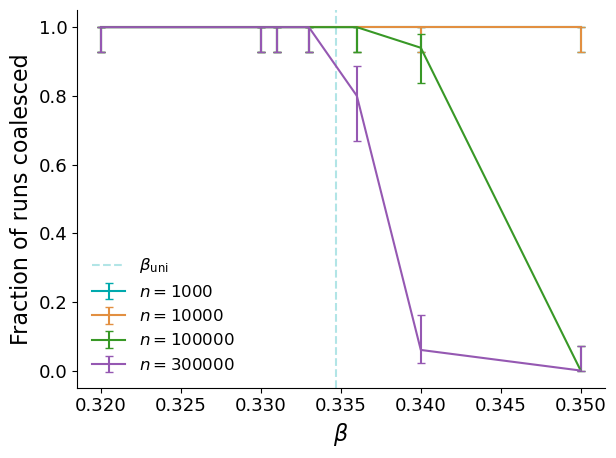

In [53]:
fig, ax = plt.subplots()

for N in sorted(df_filtered['N'].unique()):
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    if graph_type == 'EA2D' or graph_type == 'F2D':
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N**2}$', capsize=3)
    elif graph_type == 'EA3D' or graph_type == 'F3D':
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N**3}$', capsize=3)
    else:
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N}$', capsize=3)
ax.axvline(beta_uni, linestyle='--', alpha=0.3, label=rf'$\beta_\mathrm{{uni}}$')
if graph_type in ('EA2D', 'EA3D') and coup_type == 'ising':
    ax.axvline(beta_DS, linestyle='--', alpha=0.3, label=rf'$\beta_\mathrm{{DS}}$')
ax.set_xlabel(rf'$\beta$')
ax.set_ylabel('Fraction of runs coalesced')
ax.legend()
plt.tight_layout()
plt.show()

In [54]:
#fig.savefig(f'../results/{folder_data}/coal_DS_frac_{graph_type}_{coup_type}_d{d}.pdf', bbox_inches='tight')

# Scaling of coalescence times

In [55]:
max_iter_plot = 10**9
n_configs_plot = 2
n_runs_plot = 50
if graph_type == 'ER' and coup_type == 'ising':
    beta_plot = [0.24,0.252,0.26,0.27] # beta selection for plotting
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_plot = [0.32, 0.33, 0.34,0.35] # beta selection for plotting
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_plot = [0.5,0.56,0.57,0.59,0.61] #df['beta'].unique()
else:
    beta_plot = df['beta'].unique()

mask = (
    (df['n_coal'] == df['n_runs']) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['beta'].isin(beta_plot)) &
    (df['n_configs'] == n_configs_plot) &
    (df['n_runs'] == n_runs_plot) & 
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
#df_filtered

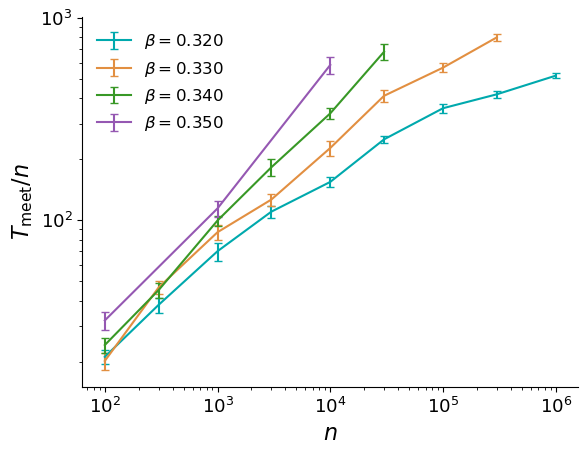

In [56]:
for beta in sorted(df_filtered['beta'].unique()):
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values
    sT = sub_df['std_coal_time'].values / np.sqrt(n_runs_plot)
    if graph_type in ('EA2D', 'F2D'):
        N = N**2
    if graph_type in ('EA3D', 'F3D'):
        N = N**3
    plt.errorbar(N, T/N,
                yerr=sT/N,
                label=rf'$\beta={beta:.3f}$',
                capsize=3)

#plt.axhline(10**9, linestyle='--', alpha=0.3)
#plt.axhline(10**8, linestyle='--', alpha=0.3)
plt.xlabel(rf'$n$')
plt.ylabel(rf'$T_\mathrm{{meet}} / n$')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()